# Steps to take for processing

## Step 1: Convert video into black and white and grayscale

This step is required to ensure that the egde filter works

## Step 2: Take the grayscale to process with Optical Flow

In [3]:
import numpy as np
import cv2

In [1]:


input_video = r'datasets\flat_global_ecco2_6840x3420_768p30-a2.mp4'

cap = cv2.VideoCapture(input_video)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"Resolution: {width}x{height}")
print(f"FPS: {fps}")

gray_output = r'datasets\flat_global_ecco2_6840x3420_768p30-a2_grayscale.mp4'
thresh_output = r'datasets\flat_global_ecco2_6840x3420_768p30-a2_bw.mp4'

fourcc = cv2.VideoWriter_fourcc(*'mp4v')

gray_writer = cv2.VideoWriter(
    gray_output,
    fourcc,
    fps,
    (width, height),
    isColor=False
)

thresh_writer = cv2.VideoWriter(
    thresh_output,
    fourcc,
    fps,
    (width, height),
    isColor=False
)

while True:
    ret, frame = cap.read()

    if not ret:
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    thresh = cv2.adaptiveThreshold(
        gray,
        255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        31,
        5
    )

    # Save outputs
    gray_writer.write(gray)
    thresh_writer.write(thresh)

    # Just in case you want to preview
    # cv2.imshow("Original", frame)
    # cv2.imshow("Grayscale", gray)
    # cv2.imshow("Threshold", thresh)

    # if cv2.waitKey(1) & 0xFF == ord('q'):
    #    break

cap.release()
gray_writer.release()
thresh_writer.release()

cv2.destroyAllWindows()

print(f"Saved grayscale video to: {gray_output}")
print(f"Saved threshold video to: {thresh_output}")

Resolution: 1368x768
FPS: 30.0
Saved grayscale video to: datasets\flat_global_ecco2_6840x3420_768p30-a2_grayscale.mp4
Saved threshold video to: datasets\flat_global_ecco2_6840x3420_768p30-a2_bw.mp4


### Using Optical Flow

Resolution and FPS should not change but just to do a sanity check

In [ ]:


input_video = r'datasets\flat_global_ecco2_6840x3420_768p30-a2_grayscale.mp4'

cap = cv2.VideoCapture(input_video)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"Resolution: {width}x{height}")
print(f"FPS: {fps}")

ret, frame = cap.read()

# Checking colour channels, apparently sometimes even though the video is greyscale, it will still be read as RGB
print(frame.dtype)

gray1 = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

frame_num = 0

# Prepping this to save all the vectors
all_u = []
all_v = []

while True:

    ret, frame = cap.read()

    if not ret:
        break


    # We need to read in greyscale, previously the value was 3 which means RGB, optical flow requires greyscale
    gray2 = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Calculating optical flow using Farneback method
    # Reference https://docs.opencv.org/4.13.0/dc/d6b/group__video__track.html#ga5d10ebbd59fe09c5f650289ec0ece5af
    flow = cv2.calcOpticalFlowFarneback(
        gray1, # first input array
        gray2, # second input array
        None,
        pyr_scale=0.5,
        levels=3,
        winsize=15,
        iterations=3,
        poly_n=5,
        poly_sigma=1.2,
        flags=0
    )
    # This is the part where every pixel has its own vector
    # For example, if our values are u[100,200] = 0.5 and v[100,200] = 0.6
    # This means that our pixel in x: 100 and y: 200 moved right by 0.5 pixels and moved up by 0.6 pixels
    u = flow[:, :, 0]
    v = flow[:, :, 1]

    # Appending is not recommended for large video files
    #all_u.append(u.astype(np.float32))
    #all_v.append(v.astype(np.float32))

    # Saving individual vector in each frame
    np.savez_compressed(
        f"datasets/frame_{frame_num:05d}.npz",
        u=u.astype(np.float32),
        v=v.astype(np.float32)
    )
    magnitude = np.sqrt(u**2 + v**2)
    
    print(
    f"Frame {frame_num}: "
        #f"Mean speed = {magnitude.mean():.4f}, "
        #f"Max speed = {magnitude.max():.4f}"
    )
    
    # This is to update to the next frame
    gray1 = gray2
    frame_num += 1

cap.release()

Resolution: 1368x768
FPS: 30.0
uint8
Frame 0: 
Frame 1: 
Frame 2: 
Frame 3: 
Frame 4: 
Frame 5: 
Frame 6: 
Frame 7: 
Frame 8: 
Frame 9: 
Frame 10: 
Frame 11: 
Frame 12: 
Frame 13: 
Frame 14: 
Frame 15: 
Frame 16: 
Frame 17: 
Frame 18: 
Frame 19: 
Frame 20: 
Frame 21: 
Frame 22: 
Frame 23: 
Frame 24: 
Frame 25: 
Frame 26: 
Frame 27: 
Frame 28: 
Frame 29: 
Frame 30: 
Frame 31: 
Frame 32: 
Frame 33: 
Frame 34: 
Frame 35: 
Frame 36: 
Frame 37: 
Frame 38: 
Frame 39: 
Frame 40: 
Frame 41: 
Frame 42: 
Frame 43: 
Frame 44: 
Frame 45: 
Frame 46: 
Frame 47: 
Frame 48: 
Frame 49: 
Frame 50: 
Frame 51: 
Frame 52: 
Frame 53: 
Frame 54: 
Frame 55: 
Frame 56: 
Frame 57: 
Frame 58: 
Frame 59: 
Frame 60: 
Frame 61: 
Frame 62: 
Frame 63: 
Frame 64: 
Frame 65: 
Frame 66: 
Frame 67: 
Frame 68: 
Frame 69: 
Frame 70: 
Frame 71: 
Frame 72: 
Frame 73: 
Frame 74: 
Frame 75: 
Frame 76: 
Frame 77: 
Frame 78: 
Frame 79: 
Frame 80: 
Frame 81: 
Frame 82: 
Frame 83: 
Frame 84: 
Frame 85: 
Frame 86: 
Frame 87: 
Frame

In [13]:
# Display a sample in OpenCV

data = np.load("./vectors/vectors/frame_00002.npz")

u = data["u"]
v = data["v"]

height, width = u.shape

canvas = np.zeros((height, width, 3), dtype=np.uint8)

step = 30

scale = 20

for y in range(0, height, step):
    for x in range(0, width, step):

        dx = u[y, x]
        dy = v[y, x]

        cv2.arrowedLine(
            canvas,
            (x, y),
            (
                int(x + dx * scale),
                int(y + dy * scale)
            ),
            (0, 255, 0),
            1,
            tipLength=0.3
        )

cv2.imshow("Optical Flow Vectors", canvas)
cv2.waitKey(0)
cv2.destroyAllWindows()

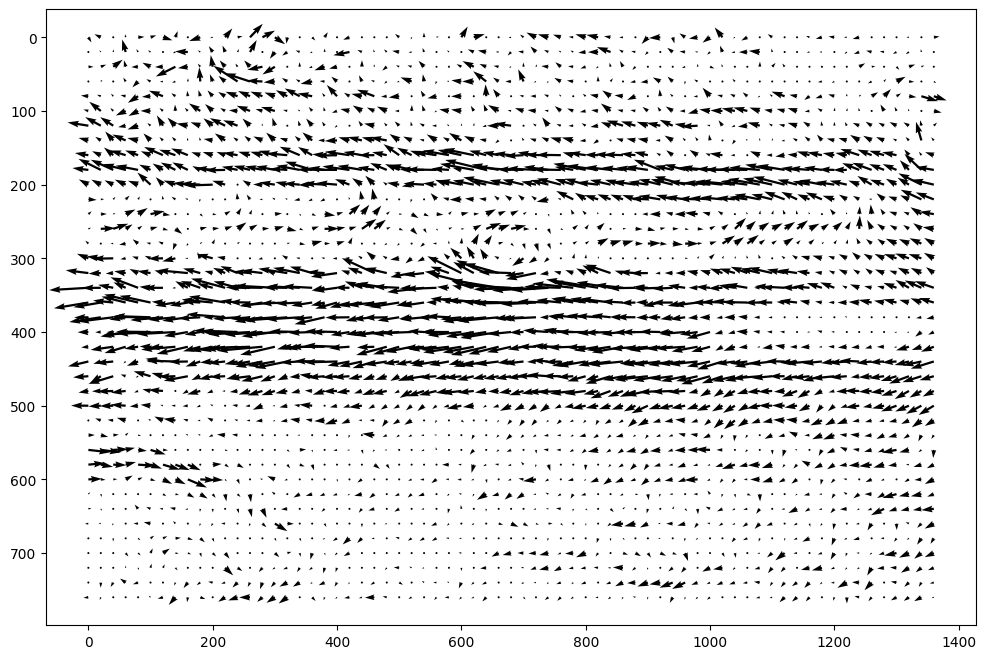

In [15]:
# Display a sample in Matplotlib

import matplotlib.pyplot as plt

data = np.load("vectors/vectors/frame_00002.npz")

u = data["u"]
v = data["v"]

step = 20

Y, X = np.mgrid[
    0:u.shape[0]:step,
    0:u.shape[1]:step
]

plt.figure(figsize=(12, 8))

plt.quiver(
    X,
    Y,
    u[::step, ::step],
    # You might notice the minus sign, this is because for image coordinates, there is an increasing Y downwards but for matplotlib, it assumes Y increases upwards, small issue to take note of
    -v[::step, ::step]
)

plt.gca().invert_yaxis()
plt.show()

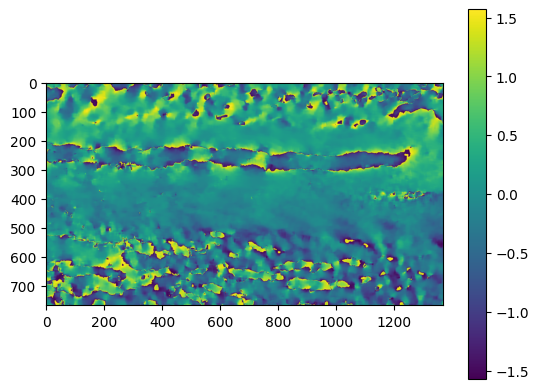

In [24]:
# direction of the current
def get_angle(u, v):
    return np.arctan(v/u)

fig,ax = plt.subplots()
plt.imshow(get_angle(u, v))
plt.colorbar()
plt.show()


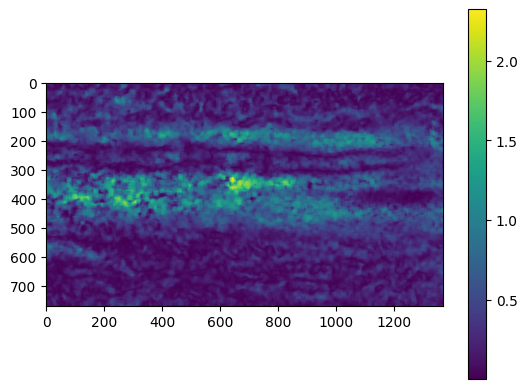

In [26]:
#speed of the current
def get_magnitude(u, v):
    return np.sqrt(np.pow(u, 2) + np.pow(v, 2))

fig, ax = plt.subplots()
plt.imshow(get_magnitude(u,v))
plt.colorbar()
plt.show()

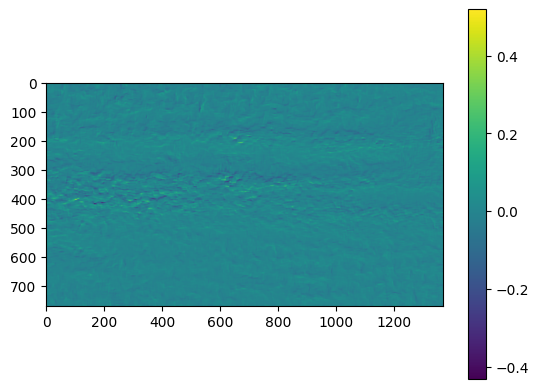

In [37]:
def get_gradient(u, ax):
    return np.gradient(u, axis = ax)

def get_divergence(u, v):
    return get_gradient(u, 0) + get_gradient(v, 1)
fig, ax = plt.subplots()
plt.imshow(get_divergence(u,v))
plt.colorbar()
plt.show()

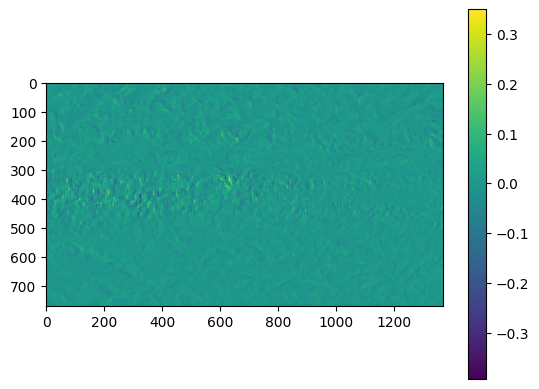

In [38]:
# curl of the current
def get_curl(u, v):
    return get_gradient(v, 0) - get_gradient(u, 1)

fig, ax = plt.subplots()
plt.imshow(get_curl(u,v))
plt.colorbar()
plt.show()

To obtain temperature of currents, we use the following scale as reference

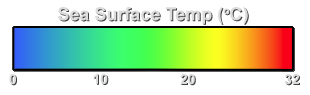

In [44]:
# Temperature of currents (TODO)
